<a href="https://colab.research.google.com/github/pallavinataraj8-glitch/Pallavi/blob/main/Copy_of_Week3_OpenCV_Live_Video_Detection_Workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🤖 OpenCV Computer Vision Workshop

> **A hands-on beginner workshop on Computer Vision using Python, OpenCV, and YOLO.**

**Environment:** Google Colab  
**Approach:** Follow the original workshop sequence. Each concept is broken into small snippets with explanations and activities.

## Important: running this workshop in Colab

Colab runs Python on a remote machine. `cv2.VideoCapture(0)` normally looks for a camera attached to that remote machine, not the camera on your laptop. For camera-based projects, this notebook uses a small browser-camera helper that asks permission and returns a frame to Python. For reliable classroom work, students can also upload a photo or short video recorded on a phone.

**Colab compatibility note:** projects that control the computer's actual mouse or keyboard (Projects 9–11) cannot control the student's local desktop from Colab. They are included in the same learning path, with the limitation clearly marked. The rest of the vision processing can be demonstrated with uploaded images/videos or browser camera frames.

## 📋 Table of Contents

1. What is Computer Vision?
2. What is OpenCV?
3. How OpenCV Works Internally
4. Why Python?
5. Environment Setup
6. Understanding Digital Images
7. Core OpenCV Operations
8. Webcam Video Capture
9. Image Filters & Edge Detection
10. Color Detection
11. Face Detection
12. YOLO Object Detection
13. Workshop Activities
14. Learning Outcomes
15. OpenCV Workshop — Project Collection (Projects 1–11)
16. All Required Libraries
17. Suggested Learning Path
18. Troubleshooting Guide
19. Final activity: test your own Week 2 `.pkl` model

---
## 👁️ What is Computer Vision?

Computer Vision is a field of AI that enables computers to **interpret and understand visual information from the world**.

**Real-world examples**
- 📱 Face unlock in smartphones
- 🚗 Self-driving cars
- 📷 Security surveillance
- 🏥 Medical image analysis
- 🕶️ Augmented reality filters

> **In simple words: Computer Vision = Teaching computers how to see.**

**Think about it:** What visual information would a robot need to detect a person, follow a line, or avoid an obstacle?

---
## 📦 What is OpenCV?

**OpenCV** stands for **Open Source Computer Vision Library**. It provides functions for image processing, detection, tracking, and camera calibration.

| Category | Examples |
|---|---|
| Image Processing | Resize, crop, blur, filter |
| Object Detection | Haar Cascades, HOG detectors |
| Face Detection | Frontal face, eye, smile |
| Motion Tracking | Optical flow |
| Camera Calibration | Lens distortion correction |

Used in robotics, autonomous vehicles, medical imaging, industrial automation, and AI research.

**Key distinction:** OpenCV is a toolkit. It includes traditional computer-vision algorithms and can also be used alongside deep-learning models such as YOLO.

---
## 🧠 How OpenCV Works Internally

OpenCV commonly processes images through a **pipeline**—like a factory assembly line where each stage transforms the image.

```text
Camera Frame
    ↓
Image Acquisition       ← Get an image/frame
    ↓
Image Representation    ← Matrix of numbers
    ↓
Preprocessing           ← Resize, denoise, convert colour
    ↓
Feature Detection       ← Find edges, corners, keypoints
    ↓
Object Detection        ← Haar Cascades / YOLO
    ↓
Visualization           ← Display the result
```

### Human Vision vs Computer Vision

```text
Human:    Eye    → Brain      → Recognize Object
Computer: Camera → OpenCV/AI  → Object Recognition
```

Humans see using eyes and the brain. Computers process camera pixels using mathematics and algorithms.

**Mini-check:** Which pipeline stage would grayscale conversion belong to? (Preprocessing.)

---
## 🐍 Why Python for OpenCV?

- ✅ Simple, readable syntax
- ✅ Rapid prototyping
- ✅ Huge AI/ML ecosystem (NumPy, TensorFlow, PyTorch)
- ✅ Strong community support

We will use Python cells directly in Colab, so students do not need to install PyCharm or create local project folders for this session.

---
## ⚙️ Environment Setup

### 1. Open the notebook in Google Colab

Use **Runtime → Run all** only after reviewing the cells, or run cells one at a time from top to bottom.

### 2. Install the libraries

Colab already provides Python. Run this cell once per fresh runtime.

In [ ]:
%pip -q install opencv-python-headless numpy matplotlib ultralytics

`opencv-python-headless` is used because Colab does not provide a normal desktop display window for `cv2.imshow()`. In this notebook, images are displayed inline with Matplotlib.

### 3. Verify installation

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("OpenCV and NumPy loaded successfully")

OpenCV Version: 4.14.0
NumPy Version: 2.1.3
OpenCV and NumPy loaded successfully


### 4. Notebook project structure

In Colab, uploaded files are stored in the current runtime temporarily. For this workshop, use the upload cells when asked for an image, video, or model file. If you need files to persist, save them to Google Drive or download them before the runtime resets.

---
## 🖼️ Understanding Digital Images

Images are stored as **arrays of numbers (pixels)**.

### Grayscale image

Each pixel is a brightness value from 0 to 255.

```text
120  100   90
200  210  180
 30   40   50
```

| Value | Meaning |
|---:|---|
| `0` | Black |
| `255` | White |

### Colour image (BGR)

OpenCV commonly stores colour channels in **BGR** order rather than RGB.

```python
[255, 0, 0]  # Blue in BGR
[0, 255, 0]  # Green in BGR
[0, 0, 255]  # Red in BGR
```

### Image shape

For an image with 720 rows, 1280 columns, and 3 colour channels, the shape is `(720, 1280, 3)`.

- First value = height
- Second value = width
- Third value = colour channels

In [ ]:
# Create a small example array so we can inspect image dimensions
sample_array = np.zeros((720, 1280, 3), dtype=np.uint8)
print("Image shape:", sample_array.shape)
print("Data type:", sample_array.dtype)

Image shape: (720, 1280, 3)
Data type: uint8


---
## 🔧 Core OpenCV Operations

### Load & display an image

Upload an image from your computer or phone. In Colab, use the upload button shown by the cell below.

Saving naman-sood-LIW4MVKIy6k-unsplash.jpg to naman-sood-LIW4MVKIy6k-unsplash (3).jpg
Loaded: naman-sood-LIW4MVKIy6k-unsplash (3).jpg
Shape: (2773, 4108, 3)


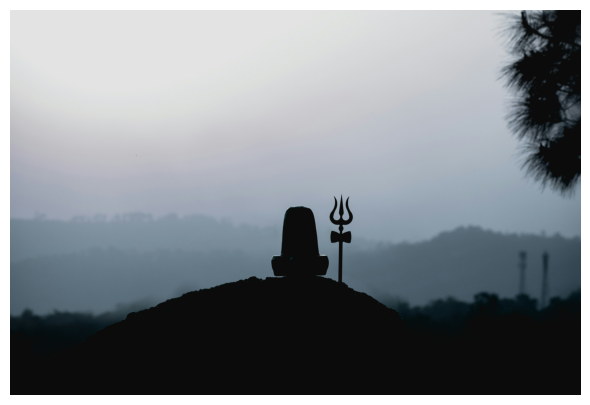

In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image
import io

uploaded = files.upload()  # Choose a JPG or PNG image
image_name = next(iter(uploaded))
img = cv2.imdecode(np.frombuffer(uploaded[image_name], np.uint8), cv2.IMREAD_COLOR)

print("Loaded:", image_name)
print("Shape:", img.shape)
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off");

In ordinary desktop Python, examples often use `cv2.imshow()`. In Colab, use Matplotlib or `cv2_imshow()` for inline output instead of opening a separate desktop window.

### Convert to grayscale

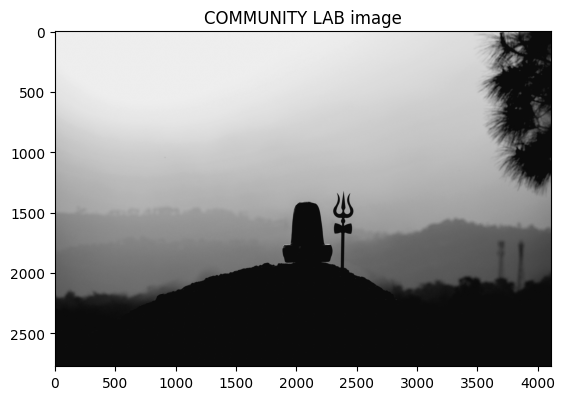

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.title("COMMUNITY LAB image")
plt.axis("on");

Grayscale keeps brightness information but removes the colour channels. Some algorithms, including the Haar face detector below, expect grayscale input.

### Resize image

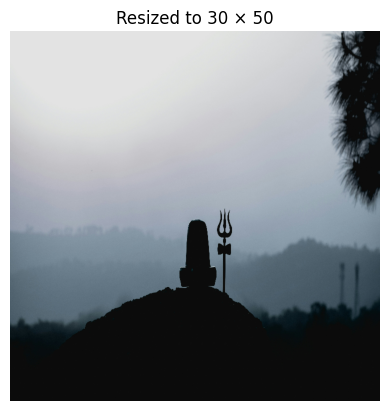

In [ ]:
resized = cv2.resize(img, (740,740))  # (width, height)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized to 30 × 50")
plt.axis("off");

Resizing changes the output dimensions. OpenCV expects `(width, height)` in `cv2.resize()`, while `img.shape` reports `(height, width, channels)`.

### Crop image

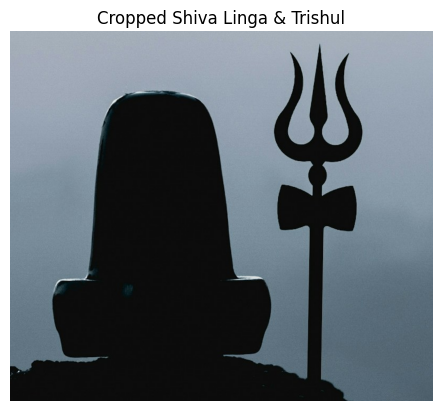

In [ ]:
crop = img[1300:2000, 1800:2600]  # y1:y2, x1:x2 capturing both Shiva Linga and Trishul
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title("Cropped Shiva Linga & Trishul")
plt.axis("off");

Cropping uses NumPy slicing: rows first (`y`), then columns (`x`). If the selected region is outside the image dimensions, the crop may be smaller or empty.

### Drawing shapes & text

| Function | Purpose |
|---|---|
| `cv2.imread()` | Reads an image from a file path |
| `cv2.cvtColor()` | Converts between colour spaces |
| `cv2.resize()` | Changes image dimensions |
| `cv2.rectangle()` | Draws a rectangle |
| `cv2.circle()` | Draws a circle |
| `cv2.putText()` | Writes text on an image |

**Note:** `cv2.imread()` reads a file path available to the Python runtime. After uploading a file in Colab, use its uploaded name or decode its bytes as demonstrated above.

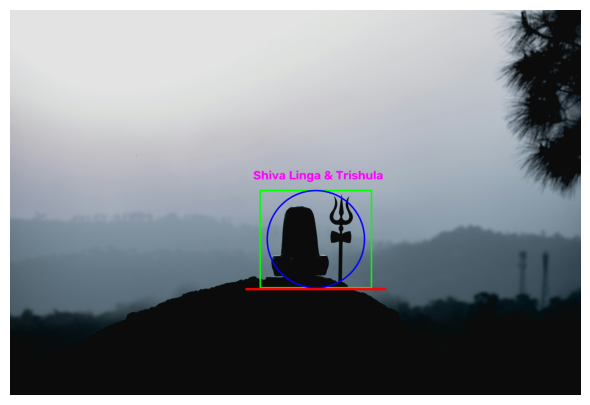

In [ ]:
drawing = img.copy()

# Rectangle
cv2.rectangle(drawing, (1800, 1300), (2600, 2000), (0, 255, 0), 10)  # pink

# Circle
cv2.circle(drawing, (2200, 1650), 350, (255, 0, 0), 10)  # black

# Line
cv2.line(drawing, (1700, 2010), (2700, 2010), (0, 0, 255), 15)  # yellow

# Text
cv2.putText(drawing, "Shiva Linga & Trishula", (1750, 1220),
            cv2.FONT_HERSHEY_SIMPLEX, 3, (255, 0, 255), 8)  # orange

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(drawing, cv2.COLOR_BGR2RGB))
plt.axis("off");

---
## 📷 Live Video in Google Colab

> **All detection activities below process a continuous live browser-camera feed—not a single captured photo.**

Colab runs Python on a remote machine, so `cv2.VideoCapture(0)` usually cannot access the webcam attached to your laptop. We use the browser's camera permission to stream frames into Python, process each frame with OpenCV/YOLO, and display the result continuously.

Run the next cell once and allow camera access. For each live demo, run its code cell and stop it with the notebook's **Interrupt execution** button (■). Live processing speed depends on your browser, connection, and runtime; YOLO may run more slowly than basic OpenCV filters.


Live-video helper ready. Each detection demo below starts its own continuous browser-camera stream.
Upload one sample image for the basic image-processing exercises.


Saving Screenshot 2026-06-04 140341.png to Screenshot 2026-06-04 140341.png
Sample image loaded for image-processing concepts. Detection demos use live video.


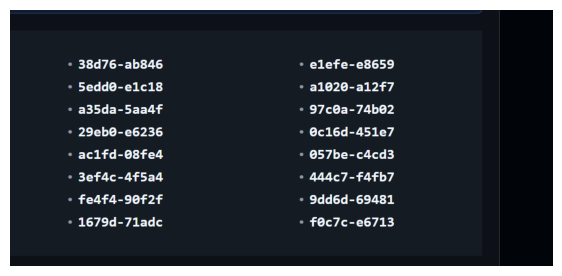

In [ ]:
from IPython.display import Javascript, display
from google.colab.output import eval_js
from base64 import b64decode

def take_browser_photo(filename="browser_photo.jpg", quality=0.9):
    js = Javascript(r'''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const title = document.createElement('p');
      title.textContent = 'Allow camera access, position yourself, then click Capture.';
      div.appendChild(title);
      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.maxWidth = '100%';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      await new Promise(resolve => {
        const button = document.createElement('button');
        button.textContent = 'Capture photo';
        div.appendChild(button);
        button.onclick = resolve;
        document.body.appendChild(div);
      });
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js(f'takePhoto({quality})')
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename



# Reusable live browser-camera loop for every detection project in this notebook.
# The browser sends one current frame at a time to the Colab Python runtime.
import time
from IPython.display import HTML, display

def run_live_video(process_frame, title="Live OpenCV Detection", delay=0.08, max_width=720):
    """Run process_frame(frame_bgr) continuously on live browser-camera frames.
    Stop by clicking Runtime → Interrupt execution (or the ■ stop button).
    """
    setup_js = r"""
    (async () => {
      if (window._mosiCvStream) {
        window._mosiCvStream.getTracks().forEach(t => t.stop());
      }
      const stream = await navigator.mediaDevices.getUserMedia({
        video: { facingMode: 'user', width: {ideal: 640}, height: {ideal: 480} }, audio: false
      });
      const video = document.createElement('video');
      video.autoplay = true; video.muted = true; video.playsInline = true;
      video.srcObject = stream;
      await video.play();
      const canvas = document.createElement('canvas');
      const ctx = canvas.getContext('2d');
      window._mosiCvStream = stream;
      window._mosiCvVideo = video;
      window._mosiCvCanvas = canvas;
      window._mosiCvGetFrame = () => {
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
        return canvas.toDataURL('image/jpeg', 0.72);
      };
      window._mosiCvStop = () => {
        if (window._mosiCvStream) window._mosiCvStream.getTracks().forEach(t => t.stop());
        window._mosiCvStream = null;
        return true;
      };
      return true;
    })()
    """
    eval_js(setup_js)
    output = display(HTML(f'<b>{title}</b><p>Starting live video… interrupt the cell to stop.</p>'), display_id=True)
    try:
        while True:
            data_url = eval_js('window._mosiCvGetFrame()')
            frame_bytes = b64decode(data_url.split(',', 1)[1])
            frame = cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR)
            if frame is None:
                continue
            processed = process_frame(frame)
            if processed is None:
                processed = frame
            h, w = processed.shape[:2]
            if w > max_width:
                processed = cv2.resize(processed, (max_width, int(h * max_width / w)))
            rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
            ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 75])
            if ok:
                import base64
                b64 = base64.b64encode(encoded).decode('ascii')
                output.update(HTML(f'<div><b>{title}</b><br><img style="max-width:100%;height:auto" src="data:image/jpeg;base64,{b64}"><p>Live feed running — use Interrupt execution (■) to stop.</p></div>'))
            time.sleep(delay)
    except KeyboardInterrupt:
        print('Live video stopped.')
    finally:
        try:
            eval_js('window._mosiCvStop && window._mosiCvStop()')
        except Exception:
            pass

print("Live-video helper ready. Each detection demo below starts its own continuous browser-camera stream.")

# Still-image upload is only for the basic image-processing lesson (resize, crop, blur, etc.).
# All detection demos below use live video instead of this uploaded still image.
from google.colab import files
print("Upload one sample image for the basic image-processing exercises.")
image_upload = files.upload()
image_name = next(iter(image_upload))
camera_img = cv2.imdecode(np.frombuffer(image_upload[image_name], np.uint8), cv2.IMREAD_COLOR)
if camera_img is None:
    raise ValueError("Could not read that image. Upload a JPG or PNG file.")
print("Sample image loaded for image-processing concepts. Detection demos use live video.")
plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(camera_img, cv2.COLOR_BGR2RGB))
plt.axis("off");


### How the live video loop works

The helper above repeatedly gets a fresh frame from the browser camera, passes it to an OpenCV/YOLO function, and refreshes the displayed result. Every detection demo uses this loop. You do not need `cv2.VideoCapture(0)` in Colab.

**To stop:** click the notebook's **Interrupt execution** button (■). The helper then stops the browser camera stream. Allow camera permission when prompted.


---
## 🌀 Image Filters & Edge Detection

### Gaussian Blur (noise removal)

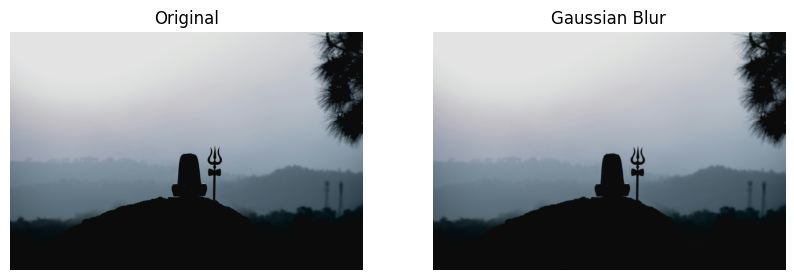

In [ ]:
# Use camera_img if defined; otherwise, fall back to the loaded img variable
active_img = camera_img if 'camera_img' in locals() else img

blur = cv2.GaussianBlur(active_img, (15, 15), 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(active_img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blur, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blur")
plt.axis("off");

Gaussian blur smooths small changes in the image. The kernel `(15, 15)` controls the blur size; use odd dimensions such as 5, 15, or 51.

### Canny Edge Detection

Edges are boundaries where image brightness changes sharply. In Canny, the two threshold values affect which edges are retained.

**Try it:** change `100, 200` to `50, 150` (more edges may appear) or `150, 250` (fewer edges may remain).


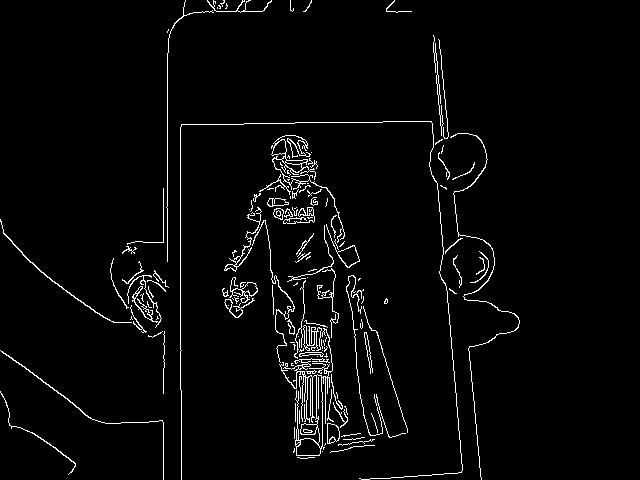

Live video stopped.


KeyboardInterrupt: 

In [13]:
def edge_processor(frame):
    edges = cv2.Canny(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 100, 200)
    return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

run_live_video(edge_processor, "Live Canny Edge Detection")

---
## 🎨 Color Detection

RGB is sensitive to lighting. We often use **HSV** because it separates hue (colour) from saturation and brightness.

### Detect blue objects


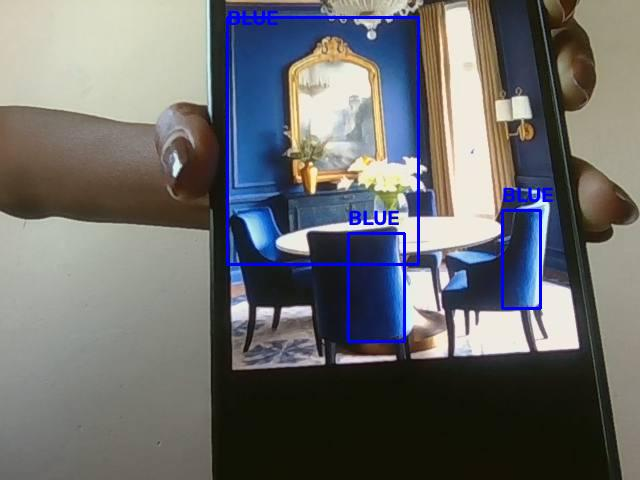

Live video stopped.


In [14]:
def blue_tracker(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    # Typical range for blue in HSV
    lower_blue = np.array([100, 150, 50])
    upper_blue = np.array([140, 255, 255])
    mask = cv2.inRange(hsv, lower_blue, upper_blue)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    output = frame.copy()
    for cnt in contours:
        if cv2.contourArea(cnt) > 500:
            x, y, w, h = cv2.boundingRect(cnt)
            # BGR for blue is (255, 0, 0)
            cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)
            cv2.putText(output, "BLUE", (x, max(25, y-8)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    return output

run_live_video(blue_tracker, "Live Blue Color Tracking")

**How it works**
1. Every live frame is converted from BGR to HSV.
2. A lower and upper blue range define the colour to detect.
3. `cv2.inRange()` creates a mask for blue pixels.
4. Contours are found and bounding boxes are drawn around larger blue regions.

**Try it:** hold a blue object in front of the live camera. To detect red or green, change the HSV range and test under your room lighting.

### `detectMultiScale` parameters

| Parameter | Meaning |
|---|---|
| `scaleFactor=1.3` | Scales the image between search passes |
| `minNeighbors=5` | Higher values generally reduce false positives |

**Try it:** change `minNeighbors=5` to `2` or `8`, then rerun the live cell. Detection may vary with lighting, angle, and image quality.

### Understand the live result

- **Class:** predicted label, such as `person`, `car`, or `bottle`
- **Bounding box:** rectangle around each detected object
- **Confidence:** model confidence for a prediction

| Model | General trade-off | Workshop use |
|---|---|---|
| `yolov8n.pt` | Smallest and fastest | Start here |
| `yolov8s.pt` | Larger, often more accurate | Optional comparison |
| `yolov8m.pt` | Larger and heavier | Optional exploration |

The next cell continuously processes the live browser-camera stream. YOLO can be slower than classical OpenCV detection in a free Colab runtime.

In [ ]:
# This section is intentionally live video, not a one-time camera capture.
# The YOLO model was loaded in the previous cell; rerun that cell to restart live detection.

---
## 🏋️ Workshop Activities

Try these in order—each builds on the last.

| # | Activity | Concepts covered |
|---:|---|---|
| 1 | Load and display an example image | Image reading and display |
| 2 | Convert an image to grayscale | `cvtColor` |
| 3 | Draw shapes and text | `rectangle`, `circle`, `putText` |
| 4 | Run live edge detection | Canny and continuous frames |
| 5 | Track a blue object live | HSV colour space, contours, bounding boxes |
| 6 | Detect faces live | Haar Cascade classifier |
| 7 | Run live YOLO object detection | Deep-learning inference |

**Classroom note:** students need to allow camera permission in the browser. If the browser camera cannot be used, a live-camera demo cannot run in Colab; upload-based media is only a fallback, not a live detection experience.

---
## 🎓 Learning Outcomes

By the end of this workshop, you should understand:

- [ ] Basics of Computer Vision
- [ ] How images are represented as numbers
- [ ] Image processing operations with OpenCV
- [ ] How live browser-camera frames are processed in Colab
- [ ] Colour detection using HSV
- [ ] Face detection using Haar Cascades
- [ ] AI-based object detection using YOLO
- [ ] How to test a previously trained image classifier, provided its expected input format is known

---
# 🎯 OpenCV Workshop — Project Collection

> **11 hands-on Computer Vision projects** built with Python, OpenCV, MediaPipe, and YOLO.

**Live-video rule:** Projects 1–8 below use a continuous browser-camera feed, not a single captured photo. Projects 9–11 also describe live camera tracking, but controlling the student's local mouse/keyboard directly is not supported by Colab; those actions are shown as visual simulations or reference concepts.

---
## 4. Motion Detection

> Detects movement by comparing consecutive live video frames.

**Difficulty:** 🟡 Intermediate  
**Concepts:** Frame differencing, thresholding, blur.

```text
Live frame now + previous frame → Absolute difference → Blur → Threshold → Motion mask
```

When a pixel changes enough between consecutive frames, it appears white in the motion mask.


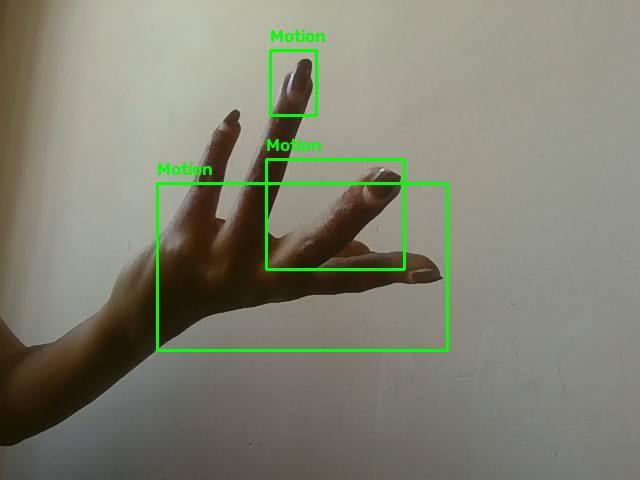

Live video stopped.


In [15]:
# Project 4: Live Motion Detection

def make_motion_processor():
    previous_gray = {"frame": None}
    def process(frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (5, 5), 0)
        output = frame.copy()
        if previous_gray["frame"] is None:
            previous_gray["frame"] = gray
            cv2.putText(output, "Move in front of camera", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)
            return output
        diff = cv2.absdiff(previous_gray["frame"], gray)
        _, mask = cv2.threshold(diff, 20, 255, cv2.THRESH_BINARY)
        mask = cv2.dilate(mask, None, iterations=2)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            if cv2.contourArea(cnt) > 700:
                x, y, w, h = cv2.boundingRect(cnt)
                cv2.rectangle(output, (x, y), (x+w, y+h), (0,255,0), 2)
                cv2.putText(output, "Motion", (x, max(25, y-8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)
        previous_gray["frame"] = gray
        return output
    return process

run_live_video(make_motion_processor(), "Project 4 — Live Motion Detection")

**Explain the stages**
- `absdiff` compares the current frame with the previous frame.
- Grayscale simplifies the comparison.
- Gaussian blur reduces small noise.
- Thresholding highlights larger changes; contours create motion boxes.

**Try it:** keep the camera still and move one object. Changes in lighting can also trigger motion.

---
## 6. Harry Potter Invisible Cloak

> Detects red cloth in a live video feed and replaces those pixels with a saved empty-background image.

**Difficulty:** 🟡 Intermediate  
**Concepts:** Background image, HSV mask, bitwise operations, morphology.

```text
Upload empty background once → Live camera frames → Detect red cloth → Replace red pixels
```

Keep the camera in the same position for the background and live video. Use a bright red cloth and steady lighting.

Upload ONE image of the empty background (no person or red cloth).


Saving walppaper.jpg to walppaper.jpg



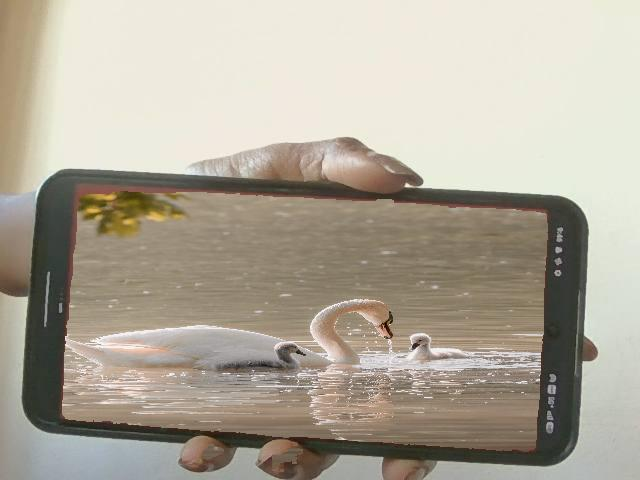

Live video stopped.


In [16]:
# Project 6: Live Invisible Cloak
from google.colab import files

print("Upload ONE image of the empty background (no person or red cloth).")
bg_upload = files.upload()
bg_name = next(iter(bg_upload))
background_original = cv2.imdecode(np.frombuffer(bg_upload[bg_name], np.uint8), cv2.IMREAD_COLOR)

def cloak_processor(frame):
    background = cv2.resize(background_original, (frame.shape[1], frame.shape[0]))
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    lower_red1, upper_red1 = np.array([0, 120, 70]), np.array([10, 255, 255])
    lower_red2, upper_red2 = np.array([170, 120, 70]), np.array([180, 255, 255])
    mask = cv2.bitwise_or(cv2.inRange(hsv, lower_red1, upper_red1), cv2.inRange(hsv, lower_red2, upper_red2))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
    mask_inv = cv2.bitwise_not(mask)
    bg_part = cv2.bitwise_and(background, background, mask=mask)
    fg_part = cv2.bitwise_and(frame, frame, mask=mask_inv)
    return cv2.add(bg_part, fg_part)

run_live_video(cloak_processor, "Project 6 — Live Invisible Cloak")

**What each step does**
- Upload an empty background image once; this is not a camera capture.
- HSV masking isolates red pixels in each live frame.
- Morphology removes some small specks.
- Bitwise operations replace red regions with pixels from the empty background.

**Tips:** keep the camera fixed, use a bright red cloth, and avoid red objects elsewhere in the scene. The effect will look imperfect if the background or camera moves.

---
## 8. Object Counter using YOLO

> Counts objects detected in each live video frame.

**Difficulty:** 🟡 Intermediate  
**Concepts:** YOLO output, bounding-box count, text overlay.

In [3]:
%pip install -q ultralytics


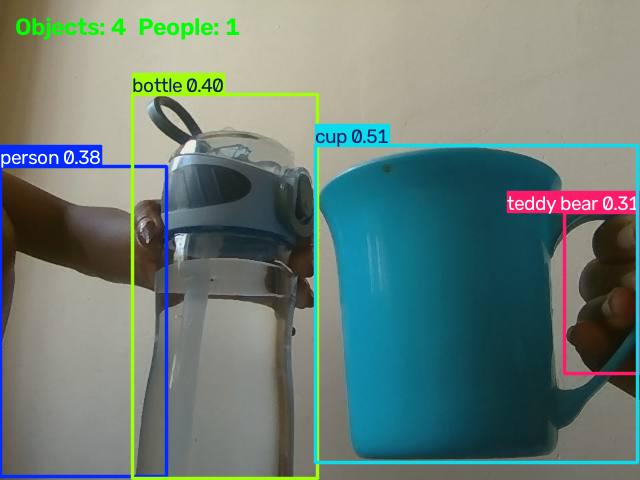

Live video stopped.


In [21]:
# Project 8: Live YOLO Object Counter

# Ensure YOLO model is loaded; load it if not defined
if 'model' not in locals() and 'model' not in globals():
    print("Loading YOLOv8 model for counting...")
    from ultralytics import YOLO
    model = YOLO("yolov8n.pt")

def yolo_counter_processor(frame):
    # Ensure model is accessible within function
    global model
    result = model(frame, verbose=False)[0]
    annotated = result.plot()
    count = len(result.boxes)
    people = sum(1 for box in result.boxes if int(box.cls[0]) == 0)
    cv2.putText(annotated, f"Objects: {count}  People: {people}", (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return annotated

run_live_video(yolo_counter_processor, "Project 8 — Live YOLO Object Counter", delay=0.12)

`len(result.boxes)` counts the detected bounding boxes in the current frame. It is not a count of unique physical objects across time: one moving object can appear in many consecutive frames.

**Count only people:** in the standard COCO model, class ID `0` represents `person`. The live overlay displays both the total boxes and people in each frame.

In [ ]:
# Optional: inside the live processor, person_count is calculated as:
# person_count = sum(1 for box in result.boxes if int(box.cls[0]) == 0)
# The live counter above displays this value on every frame.

---
## 🚀 YOLO Object Detection

**YOLO** means “You Only Look Once.” It is a deep-learning model that predicts object classes, bounding boxes, and confidence scores.

YOLO can detect common classes such as people, cars, bottles, phones, chairs, and animals.

### Classical CV vs AI vision

| Approach | Pipeline |
|---|---|
| Classical OpenCV | Image → hand-crafted features/rules → detection |
| Deep learning (YOLO) | Image → neural network → object detections |

### Run YOLO on an image

The first run downloads the model weights. This may take a little time and requires an internet connection in the Colab runtime.


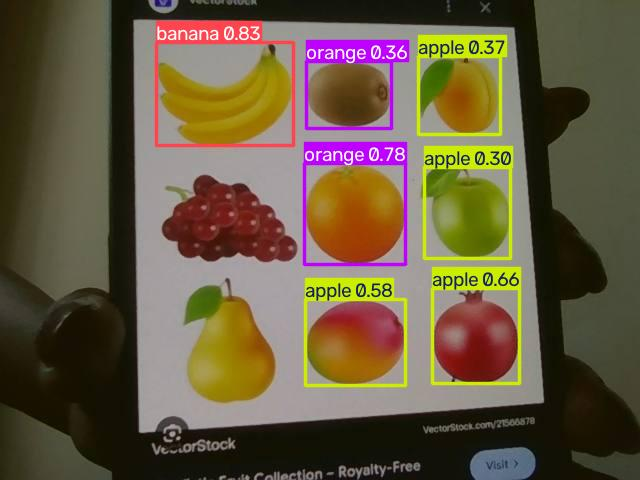

Live video stopped.


In [22]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # small, fast model

def yolo_processor(frame):
    result = model(frame, verbose=False)[0]
    return result.plot()

run_live_video(yolo_processor, "Live YOLO Object Detection", delay=0.12)

---
## 9. Eye Controlled Mouse

> Uses facial landmarks to estimate eye/iris position and move the cursor.

**Difficulty:** 🔴 Advanced  
**Concepts:** MediaPipe Face Mesh, eye landmarks, cursor mapping, blink detection.

**Important Colab limitation:** PyAutoGUI in a cloud runtime cannot control the mouse on the student's local desktop. This project is kept in the workshop sequence as a design/reference activity, not a runnable local-mouse-control exercise in Colab.

### Core idea

```text
Camera → Face landmarks → Track iris → Map coordinates to screen
```

Students can discuss the pipeline or build a visual demonstration that draws the iris landmark on an image. A true cursor-control version needs a supported local environment with camera and desktop permissions.

---
## 10. Mouse Control using Eye Tracking

> An enhanced version of Project 9, with clearer structure and room to add gestures.

**Difficulty:** 🔴 Advanced

This project uses the same concepts as Project 9. The key extension is project organization and future improvements such as smoothing cursor movement, adding calibration, or distinguishing gestures.

**Colab limitation:** direct local mouse control is not available from the remote notebook. Treat this as an extension/design task unless students run it in a supported local desktop environment.

---
## 11. Virtual Keyboard with Hand Gesture Control

> A virtual keyboard rendered on screen—type by pointing at keys and pinching fingers.

**Difficulty:** 🔴 Advanced  
**Concepts:** Hand landmarks, gesture recognition, virtual UI, keyboard simulation.

**Colab limitation:** sending keypresses to the student's local operating system is not supported from a remote notebook. The interaction pipeline can still be studied:

```text
Camera → Hand landmarks → Finger position → Hover key → Pinch = key press
```

### Concepts to explain
1. **Hand tracking:** estimate landmarks for each finger.
2. **Keyboard layout:** represent keys as rectangles on an image.
3. **Hover detection:** check whether the index fingertip is inside a key rectangle.
4. **Pinch detection:** measure the distance between two fingertips.
5. **Action:** a local application can send the corresponding keypress.

For a Colab-only activity, students can draw a virtual keyboard image and identify which key rectangle contains a supplied fingertip coordinate. Do not run code that sends keystrokes to the local computer from Colab.

---
## 📦 All Required Libraries

Install only the libraries needed for the projects you actually run in Colab.

In [ ]:
%pip -q install opencv-python-headless numpy matplotlib ultralytics

| Library | Used in |
|---|---|
| `opencv-python-headless` | OpenCV image processing in Colab |
| `numpy` | Image arrays, masks, and calculations |
| `matplotlib` | Display images inline |
| `ultralytics` | YOLO detection |
| `mediapipe` | Optional advanced landmark activities; version/runtime compatibility can vary |
| `pyautogui` | Local desktop mouse control only—not local control from Colab |
| `cvzone` | Optional helper library for local hand-tracking projects |
| `pynput` | Local keyboard control only—not local control from Colab |

The original desktop install command is:
```bash
pip install opencv-python numpy ultralytics mediapipe pyautogui cvzone pynput
```
In Colab, prefer the headless OpenCV package and avoid installing desktop-control libraries unless you are only reviewing their code. Some libraries may not support every Colab Python runtime.

---
## 🗺️ Suggested Learning Path

```text
Project 1 → 2 → 3      (Beginner: basic OpenCV)
     ↓
Project 4 → 5 → 6      (Intermediate: frame operations + masking)
     ↓
Project 7 → 8           (AI: YOLO detection)
     ↓
Project 9 → 10 → 11    (Advanced: landmarks + gesture control)
```

**Suggested classroom pacing:** first teach the core workshop sections, then select projects according to available time and student readiness. Projects 9–11 can be discussed or prototyped visually in Colab; local desktop interaction needs a different runtime.

---
## ❓ Troubleshooting Guide

### 📷 Live Webcam & Camera Issues

| Problem | What to try |
|---|---|
| Browser camera permission denied | Click the site permission icon near the address bar, allow camera access, then rerun the live demo |
| Camera unavailable | Close other apps using the camera and check browser/device permissions |
| `cv2.VideoCapture(0)` returns no frames in Colab | Expected in many cases: the webcam is attached to the browser, not the remote runtime; use the live browser-camera helper |
| Live feed is slow | Reduce camera resolution or choose a simpler detector; YOLO can be slower than basic OpenCV operations |
| Need to stop a demo | Click Runtime → Interrupt execution (■); the helper also stops the browser camera stream |
| Browser camera feature unsupported | Colab cannot provide a true live feed in that case; use a local Python environment for live webcam work |

**Remember:** a phone and lab computer being on the same Wi-Fi does not automatically make the phone camera available to Colab.

### 📦 Installation Issues

| Problem | Fix |
|---|---|
| OpenCV import error | Rerun the installation cell, then use Runtime → Restart session if needed |
| `cv2.imshow()` errors | Use Matplotlib or inline display instead of desktop windows |
| `ModuleNotFoundError` | Run the install cell in the same Colab notebook/runtime |
| Package version conflict | Restart the runtime and install only the packages required by this notebook |

### 🤖 YOLO Issues

| Problem | Fix |
|---|---|
| First run takes time | YOLO downloads model weights the first time |
| Runtime has no internet | Upload an available compatible model file, or skip YOLO until internet is available |
| Detection is slow | Start with `yolov8n.pt`; use a GPU runtime if permitted |
| Detection seems inaccurate | Try a clearer image, better lighting, or compare a larger model |

### 🧥 Invisible Cloak Issues

| Problem | Fix |
|---|---|
| Cloth not replaced | Check the red mask; change HSV limits for your lighting |
| Background appears incorrectly | Use a matching background image and foreground image with the camera in the same position |
| Mask has noisy specks | Try a larger morphology kernel, such as `(5, 5)` |
| Other red objects disappear | Colour masking selects red pixels, not specifically the cloth |

### 🐛 Common Coding Mistakes

| Mistake | What happens | Fix |
|---|---|---|
| `cv2.waitKey(0)` inside a video loop | A desktop loop pauses until a key is pressed | Use `cv2.waitKey(1)` in a local desktop program |
| Forgetting `cap.release()` | Camera may remain occupied in local Python | Release the camera in a `finally` block |
| Wrong `cv2.resize()` order | Image may look stretched or have unexpected dimensions | Use `(width, height)` |
| Confused by `img.shape` | Dimensions appear reversed | It is `(height, width, channels)` |
| BGR/RGB mix-up | Displayed colours may look wrong | Convert with `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` for Matplotlib |
| Empty/invalid upload | OpenCV cannot decode the file | Confirm a valid JPG/PNG/MP4 was uploaded |

---
## 🎯 Final Activity: Test Your Own Week 2 `.pkl` Classifier

You trained an image classifier in Week 2. This final section lets you upload the saved `.pkl` model and test it with an image.

**Important:** a `.pkl` file may contain a scikit-learn classifier, a preprocessing pipeline, or another Python object. The correct image size, colour order, normalization, and flattening method must match the way the model was trained. The generic example below is only a first inspection—not a guarantee that every model will accept a flattened image.

In [25]:
# Upload the .pkl model created in Week 2
from google.colab import files
import pickle

model_upload = files.upload()
model_file = next(iter(model_upload))

with open(model_file, "rb") as f:
    student_model = pickle.load(f)

print("Loaded file:", model_file)
print("Loaded object type:", type(student_model))
print("Model object:")
print(student_model)

Saving mask_classifier.pkl to mask_classifier.pkl
Loaded file: mask_classifier.pkl
Loaded object type: <class 'sklearn.svm._classes.SVC'>
Model object:
SVC(kernel='linear')


### Step 1: inspect what the model expects

If the model has `n_features_in_`, it may tell you how many input features it expects. If it is a scikit-learn `Pipeline`, inspect its steps. Do not assume all `.pkl` files use the same format.

In [26]:
print("Object type:", type(student_model))
print("Expected feature count:", getattr(student_model, "n_features_in_", "Not exposed"))
print("Has predict():", hasattr(student_model, "predict"))

Object type: <class 'sklearn.svm._classes.SVC'>
Expected feature count: 12288
Has predict(): True


### Step 2: upload a test image

Upload a test image for your classifier (or cancel/close to use a fallback image):


Saving walppaper.jpg to walppaper (1).jpg
Successfully loaded uploaded image: walppaper (1).jpg


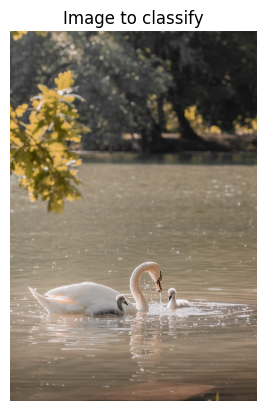

In [30]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt
import numpy as np

try:
    print("Upload a test image for your classifier (or cancel/close to use a fallback image):")
    test_upload = files.upload()
    if test_upload:
        test_name = next(iter(test_upload))
        test_img = cv2.imdecode(np.frombuffer(test_upload[test_name], np.uint8), cv2.IMREAD_COLOR)
        print(f"Successfully loaded uploaded image: {test_name}")
    else:
        raise ValueError("No image uploaded.")
except Exception as e:
    # Fallback to previously loaded images in the notebook session
    if 'camera_img' in locals() or 'camera_img' in globals():
        test_img = camera_img
        print("No new upload detected. Falling back to the previously uploaded 'camera_img'.")
    elif 'img' in locals() or 'img' in globals():
        test_img = img
        print("No new upload detected. Falling back to the previously uploaded 'img'.")
    else:
        print("Error: No test image could be loaded or found as a fallback.")
        raise e

if 'test_img' in locals() or 'test_img' in globals():
    plt.imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
    plt.title("Image to classify")
    plt.axis("off")
    plt.show()

### Step 3: example preprocessing for a simple flattened grayscale classifier

Use this only if your Week 2 training code used **grayscale → resize to 8×8 → flatten**. If your project used a different image size or preprocessing, change this cell to match that exact training pipeline.

In [33]:
# Preprocess the newly uploaded image to match the model's 12288 features
color_test = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
resized_test = cv2.resize(color_test, (64, 64))
features = resized_test.reshape(1, -1)

print("Input feature shape:", features.shape)

if hasattr(student_model, "predict"):
    try:
        prediction = student_model.predict(features)
        print("Prediction:", prediction)
        if hasattr(student_model, "predict_proba"):
            try:
                print("Probabilities:", student_model.predict_proba(features))
            except Exception as exc:
                print("Probability output unavailable:", exc)
    except Exception as exc:
        print("Prediction failed. This usually means the preprocessing/feature count does not match the model.")
        print("Error:", repr(exc))
else:
    print("This loaded object does not expose predict(). Inspect the object and its training code.")

Input feature shape: (1, 12288)
Prediction: [0]


In [34]:
import json

notebook_path = "/content/Copy of Team5_Mask_NoMask_Classifieroriginal.ipynb"

try:
    with open(notebook_path, "r", encoding="utf-8") as f:
        nb_data = json.load(f)

    print("Searching your Week 2 notebook for class/label mapping keywords...\n")
    found_lines = []
    for i, cell in enumerate(nb_data.get("cells", [])):
        if cell.get("cell_type") == "code":
            source_lines = cell.get("source", [])
            for line_no, line in enumerate(source_lines):
                # Search for typical mapping/label keywords
                if any(kw in line.lower() for kw in ["class_", "label_", "mapping", "categories", "target", "mask", "nomask"]):
                    found_lines.append(f"Cell {i}, Line {line_no + 1}: {line.strip()}")

    if found_lines:
        for line in found_lines[:25]:  # show top 25 matches
            print(line)
    else:
        print("No explicit class mapping keywords found automatically. Let's look at the folder names or labels loaded from your datasets instead.")
except Exception as e:
    print(f"Could not read the notebook: {e}")

Searching your Week 2 notebook for class/label mapping keywords...

Cell 0, Line 13: path = snapshot_download("Kai1014/facemask-kaggle", repo_type="dataset")
Cell 0, Line 24: # 2. Work out labels: 0 = mask, 1 = no_mask (skip "incorrect")
Cell 0, Line 28: if "without" in n or "no_mask" in n or "nomask" in n: return 1
Cell 0, Line 29: if "with" in n or n == "mask": return 0
Cell 0, Line 52: CLASSES, IMG_SIZE = ["mask", "no_mask"], 64
Cell 0, Line 60: print("Data:", X.shape, "| mask:", (y == 0).sum(), "| no_mask:", (y == 1).sum())
Cell 0, Line 71: joblib.dump(model, "mask_classifier.joblib")
Cell 0, Line 72: files.download("mask_classifier.joblib")
Cell 0, Line 73: print("Model saved. Classes: 0 = mask, 1 = no_mask")
Cell 3, Line 2: files.download("mask_classifier.joblib")


### Step 4: compare with the original Week 2 training code

Before concluding the model is wrong, confirm:

- [ ] Same image dimensions as training
- [ ] Same colour conversion (grayscale or colour)
- [ ] Same channel order (RGB/BGR)
- [ ] Same normalization or pixel scaling
- [ ] Same flattening or feature-extraction method
- [ ] Same label/class mapping

**Security note:** only load `.pkl` files you created or trust. Pickle files can execute code when loaded.

### Student reflection

1. Which OpenCV operation changed your image the most?
2. What is the difference between a mask and a bounding box?
3. How does YOLO differ from Haar Cascade face detection?
4. What preprocessing did your Week 2 classifier expect?
5. What would you improve if you had more training images?

---

<div align="center">

**Happy Coding! 🚀**

*OpenCV Computer Vision Workshop — Google Colab Edition*

</div>